In [ ]:
!pip -q install pystac-client planetary-computer rasterio matplotlib numpy pandas

In [ ]:

from pystac_client import Client

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

# Kanpur study area: [west, south, east, north]
bbox = [80.2, 26.3, 80.5, 26.6]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2025-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=10
)

items = list(search.items())

print("Scenes found:", len(items))

for item in items[:5]:
    print(
        "Date:", item.datetime.date(),
        "| Cloud:", round(item.properties["eo:cloud_cover"], 2), "%",
        "| ID:", item.id
    )


Scenes found: 10
Date: 2025-12-13 | Cloud: 4.56 % | ID: S2A_MSIL2A_20251213T052241_R062_T44RMQ_20251213T083109
Date: 2025-12-13 | Cloud: 3.69 % | ID: S2B_MSIL2A_20251213T051119_R019_T44RMQ_20251213T070912
Date: 2025-12-11 | Cloud: 0.01 % | ID: S2C_MSIL2A_20251211T052231_R062_T44RMQ_20251211T091614
Date: 2025-12-06 | Cloud: 0.0 % | ID: S2B_MSIL2A_20251206T052109_R062_T44RMQ_20251206T072603
Date: 2025-12-03 | Cloud: 1.78 % | ID: S2B_MSIL2A_20251203T051059_R019_T44RMQ_20251203T071459


In [ ]:

# Pick the scene with the lowest cloud cover
items = sorted(
    items,
    key=lambda item: item.properties["eo:cloud_cover"]
)

item = items[0]

print("Selected date:", item.datetime.date())
print("Cloud cover:", round(item.properties["eo:cloud_cover"], 2), "%")
print("Scene ID:", item.id)


Selected date: 2025-12-06
Cloud cover: 0.0 %
Scene ID: S2B_MSIL2A_20251206T052109_R062_T44RMQ_20251206T072603


In [ ]:

# Check which bands are available
print("Available bands:")

for band in ["B02", "B03", "B04", "B08", "B11", "SCL"]:
    if band in item.assets:
        print(band, "-", item.assets[band].title)
    else:
        print(band, "- not available")


Available bands:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
B11 - Band 11 - SWIR (1.6) - 20m
SCL - Scene classfication map (SCL)


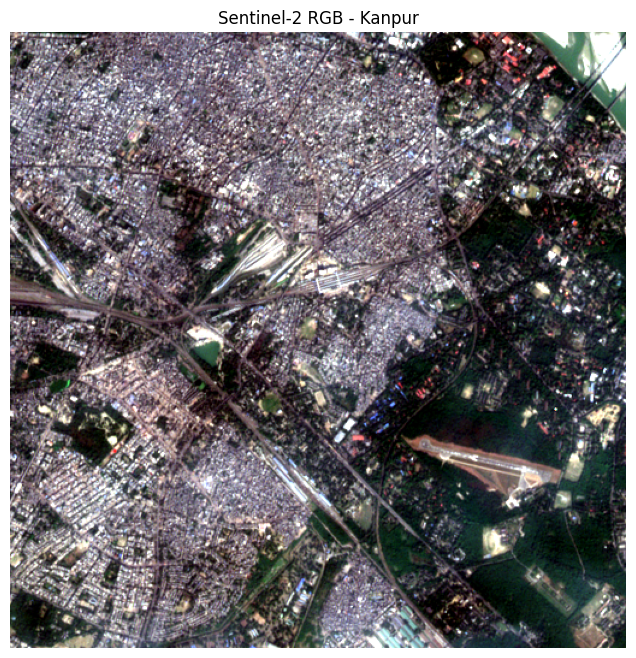

Crop shape: (512, 512)


In [ ]:

import planetary_computer
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.windows import Window
from rasterio.warp import transform
from rasterio.transform import rowcol

# Open a small area around the centre of Kanpur
signed_item = planetary_computer.sign(item)

with rasterio.open(signed_item.assets["B04"].href) as src:
    x, y = transform(
        "EPSG:4326", src.crs,
        [80.35], [26.45]
    )
    row, col = rowcol(src.transform, x[0], y[0])

    window = Window(col - 256, row - 256, 512, 512)

    red = src.read(1, window=window).astype("float32")
    profile = src.profile

with rasterio.open(signed_item.assets["B03"].href) as src:
    green = src.read(1, window=window).astype("float32")

with rasterio.open(signed_item.assets["B02"].href) as src:
    blue = src.read(1, window=window).astype("float32")

# Stretch the values so the image is easier to view
def stretch(band):
    low, high = np.percentile(band, [2, 98])
    return np.clip((band - low) / (high - low + 1e-6), 0, 1)

rgb = np.dstack([stretch(red), stretch(green), stretch(blue)])

plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.title("Sentinel-2 RGB - Kanpur")
plt.axis("off")
plt.show()

print("Crop shape:", red.shape)


NDVI range: -0.20258768 to 0.63110006


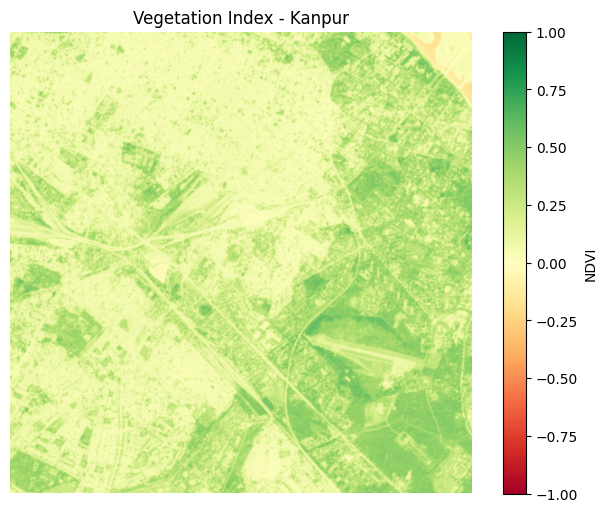

In [ ]:

# Calculate NDVI
with rasterio.open(signed_item.assets["B08"].href) as src:
    nir = src.read(1, window=window).astype("float32")

ndvi = (nir - red) / (nir + red + 1e-6)

print("NDVI range:", np.nanmin(ndvi), "to", np.nanmax(ndvi))

plt.figure(figsize=(8, 6))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("Vegetation Index - Kanpur")
plt.axis("off")
plt.show()


In [ ]:

# Combine the bands and NDVI into one array
features = np.stack([blue, green, red, nir, ndvi], axis=-1)

# Remove pixels with invalid values
valid_mask = np.isfinite(features).all(axis=-1)

print("Feature array shape:", features.shape)
print("Valid pixels:", valid_mask.sum())
print("Features: Blue, Green, Red, NIR, NDVI")


Feature array shape: (512, 512, 5)
Valid pixels: 262144
Features: Blue, Green, Red, NIR, NDVI


In [ ]:

# Check the SCL labels in the same area
with rasterio.open(signed_item.assets["SCL"].href) as src:
    print("SCL resolution:", src.res)
    print("SCL size:", src.width, "x", src.height)

    x, y = transform(
        "EPSG:4326", src.crs,
        [80.35], [26.45]
    )
    row_scl, col_scl = rowcol(src.transform, x[0], y[0])

    scl_window = Window(
        col_scl - 128, row_scl - 128, 256, 256
    )
    scl = src.read(1, window=scl_window)

values, counts = np.unique(scl, return_counts=True)

print("SCL values in crop:")
for value, count in zip(values, counts):
    print(int(value), "-", int(count), "pixels")


SCL resolution: (20.0, 20.0)
SCL size: 5490 x 5490
SCL values in crop:
4 - 6997 pixels
5 - 57861 pixels
6 - 678 pixels


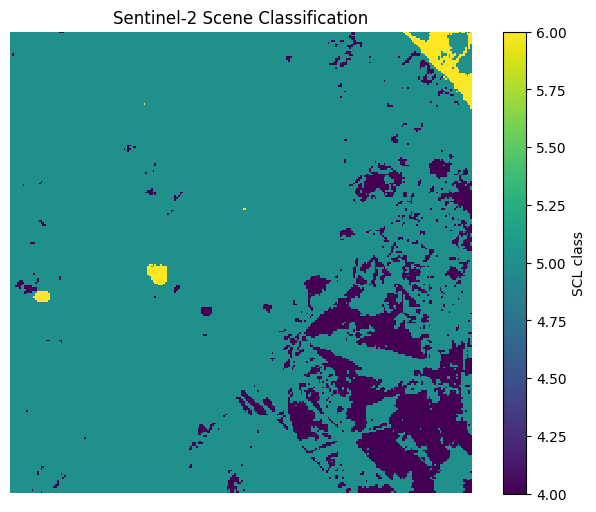

Vegetation: 10.68%
Not vegetated: 88.29%
Water: 1.03%


In [ ]:

# Plot the classes found in this crop
plt.figure(figsize=(8, 6))
plt.imshow(scl, cmap="viridis", interpolation="nearest")
plt.colorbar(label="SCL class")
plt.title("Sentinel-2 Scene Classification")
plt.axis("off")
plt.show()

# Check the share of each class
for value, count in zip(values, counts):
    label = {4: "Vegetation", 5: "Not vegetated", 6: "Water"}
    print(f"{label.get(int(value), 'Other')}: {count / scl.size * 100:.2f}%")


Aligned SCL shape: (512, 512)
Class counts:
4 : 28205
5 : 231206
6 : 2733


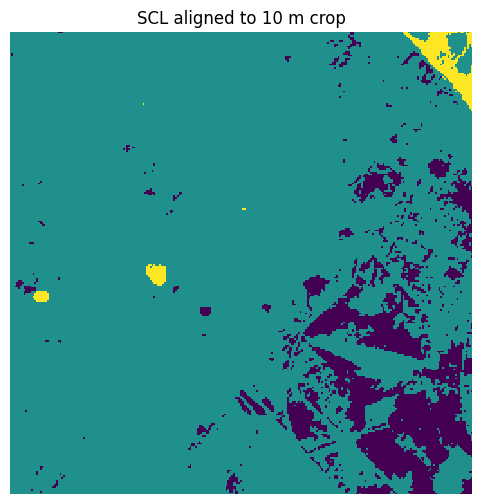

In [ ]:

from rasterio.warp import reproject, Resampling

# Match the SCL grid to the RGB crop
scl_10m = np.zeros((512, 512), dtype=np.uint8)

with rasterio.open(signed_item.assets["B04"].href) as red_src:
    x, y = transform(
        "EPSG:4326", red_src.crs,
        [80.35], [26.45]
    )
    row, col = rowcol(red_src.transform, x[0], y[0])
    window = Window(col - 256, row - 256, 512, 512)

    crop_transform = red_src.window_transform(window)
    crop_crs = red_src.crs

with rasterio.open(signed_item.assets["SCL"].href) as scl_src:
    reproject(
        source=rasterio.band(scl_src, 1),
        destination=scl_10m,
        src_transform=scl_src.transform,
        src_crs=scl_src.crs,
        src_nodata=0,
        dst_transform=crop_transform,
        dst_crs=crop_crs,
        dst_nodata=0,
        resampling=Resampling.nearest
    )

values_10m, counts_10m = np.unique(
    scl_10m, return_counts=True
)

print("Aligned SCL shape:", scl_10m.shape)
print("Class counts:")

for value, count in zip(values_10m, counts_10m):
    print(int(value), ":", int(count))

plt.figure(figsize=(7, 6))
plt.imshow(scl_10m, interpolation="nearest")
plt.title("SCL aligned to 10 m crop")
plt.axis("off")
plt.show()


In [11]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Keep only the three classes we want to model
class_mask = np.isin(scl_10m, [4, 5, 6]) & valid_mask

X = features[class_mask]
y = scl_10m[class_mask]

# Use a smaller sample to keep training quick
rng = np.random.default_rng(42)
n_samples = min(20000, len(y))
idx = rng.choice(len(y), size=n_samples, replace=False)

X_sample = X[idx]
y_sample = y[idx]

print("Samples:", len(y_sample))
print("Class labels:", np.unique(y_sample))


Samples: 20000
Class labels: [4 5 6]


In [12]:

# Split the samples into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

# Train the model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Check performance on the test set
y_pred = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[4, 5, 6],
    target_names=["Vegetation", "Not vegetated", "Water"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[4, 5, 6]))


Test accuracy: 0.9535

Classification report:
               precision    recall  f1-score   support

   Vegetation       0.82      0.81      0.82       447
Not vegetated       0.97      0.98      0.97      3515
        Water       0.89      0.45      0.60        38

     accuracy                           0.95      4000
    macro avg       0.90      0.75      0.80      4000
 weighted avg       0.95      0.95      0.95      4000

Confusion matrix:
[[ 363   84    0]
 [  79 3434    2]
 [   0   21   17]]


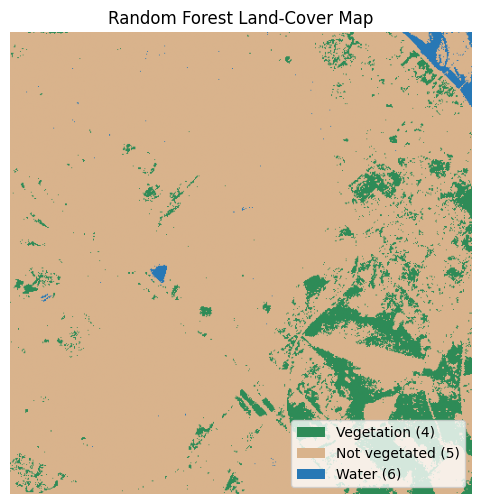

In [13]:

# Predict the class of each pixel
predicted_map = np.zeros((512, 512), dtype=np.uint8)

pixel_data = features.reshape(-1, 5)
pixel_mask = valid_mask.ravel()

predicted_map.ravel()[pixel_mask] = model.predict(
    pixel_data[pixel_mask]
)

# Show the predicted map
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colors = ["#2e8b57", "#d9b38c", "#2878b5"]
cmap = ListedColormap(colors)

plt.figure(figsize=(8, 6))
plt.imshow(predicted_map, cmap=cmap, vmin=4, vmax=6)
plt.title("Random Forest Land-Cover Map")
plt.axis("off")

legend_items = [
    Patch(facecolor=colors[0], label="Vegetation (4)"),
    Patch(facecolor=colors[1], label="Not vegetated (5)"),
    Patch(facecolor=colors[2], label="Water (6)")
]
plt.legend(handles=legend_items, loc="lower right")
plt.show()


In [14]:

# Count the pixels assigned to each class
class_names = {
    4: "Vegetation",
    5: "Not vegetated",
    6: "Water"
}

total = np.sum(predicted_map > 0)

for class_id, name in class_names.items():
    count = np.sum(predicted_map == class_id)
    percentage = count / total * 100

    print(f"{name}: {count} pixels ({percentage:.2f}%)")


Vegetation: 27390 pixels (10.45%)
Not vegetated: 232988 pixels (88.88%)
Water: 1766 pixels (0.67%)


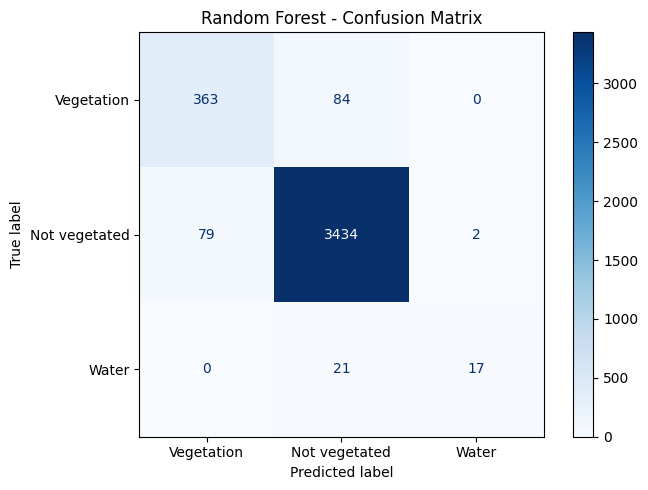

In [15]:

from sklearn.metrics import ConfusionMatrixDisplay

# Compare the predicted labels with the test labels
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[4, 5, 6],
    display_labels=["Vegetation", "Not vegetated", "Water"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()



## Results and Interpretation

A Random Forest classifier was trained using Sentinel-2 spectral bands (Blue, Green, Red and NIR) and NDVI. The Scene Classification Layer (SCL) was used to create three reference classes: vegetation, not vegetated and water.

The model achieved 95.35% test accuracy on the sampled SCL labels. However, performance varied across classes. The model performed well on the not-vegetated class, while water detection was weaker, with a recall of 0.45.

The confusion matrix shows that 21 water samples were incorrectly classified as not vegetated. This suggests that water is difficult to distinguish from other surfaces using the current features and training setup.

### Limitations

- SCL labels are derived from the same Sentinel-2 product, not independent ground-truth observations.
- The classes are imbalanced, with far fewer water samples than not-vegetated samples.
- The model currently distinguishes three broad classes; it does not separately identify built-up areas and bare soil.
- Results are based on one small crop and one acquisition date, so they should not be generalized to all of Kanpur.

### Next steps

Evaluate the model with independent reference data, improve water-class representation, and test the workflow on additional dates or locations.


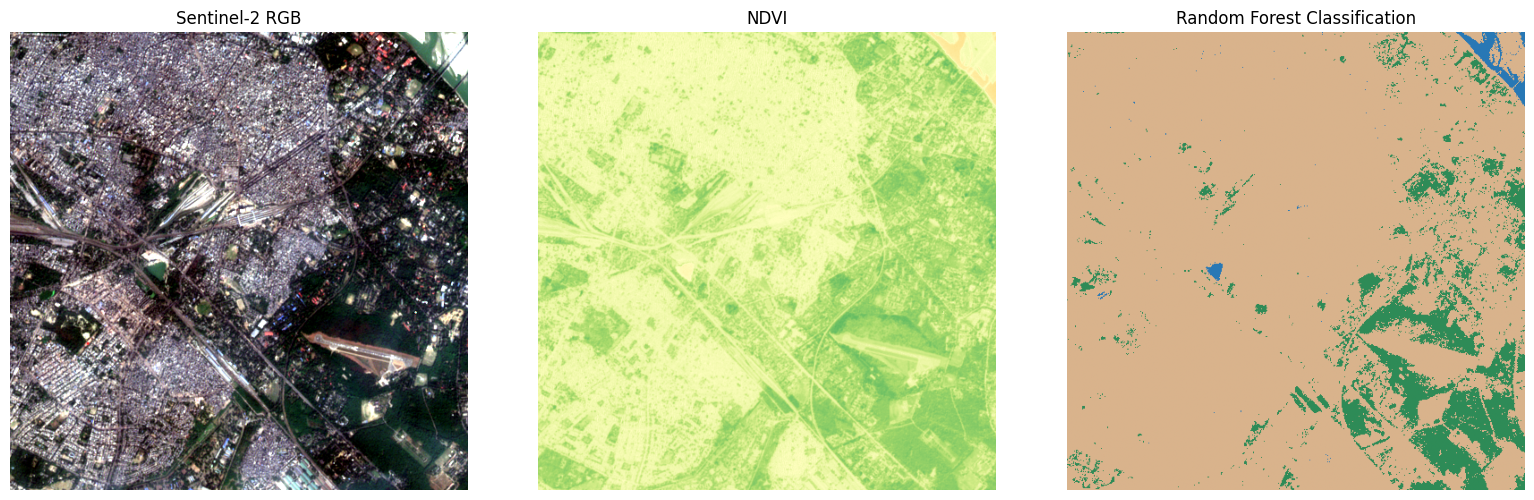

In [16]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Show the original satellite image
axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB")

# Show vegetation patterns
axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("NDVI")

# Show the predicted classes
axes[2].imshow(predicted_map, cmap=cmap, vmin=4, vmax=6)
axes[2].set_title("Random Forest Classification")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


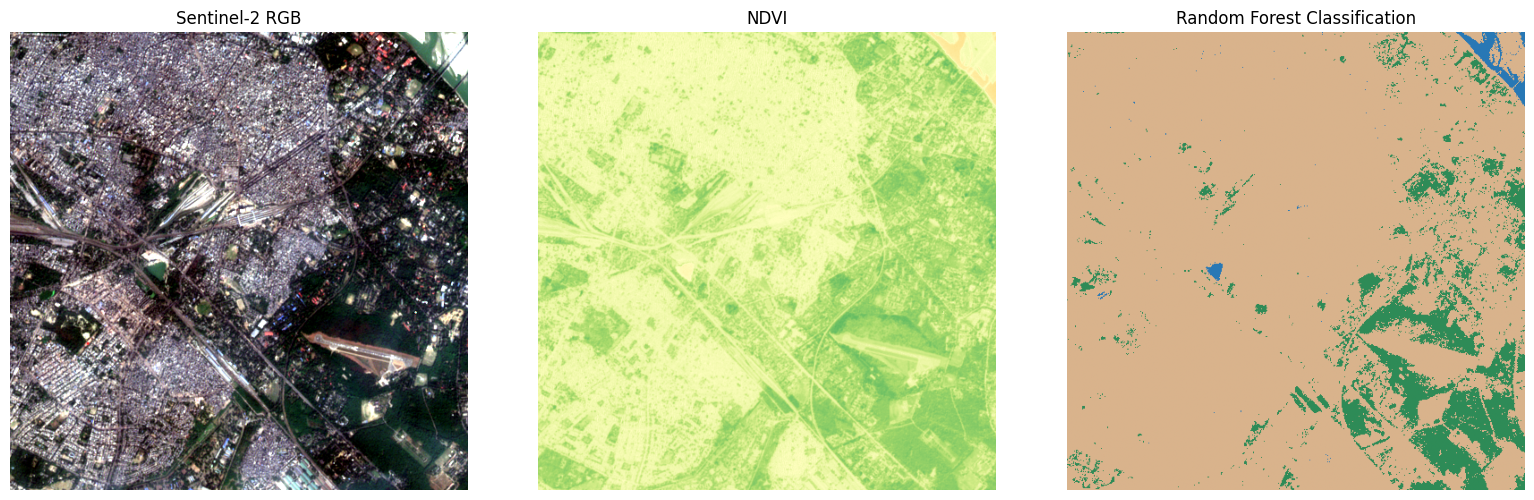

Saved: landcover_comparison.png


In [17]:

# Save the comparison figure for the project README
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB")

axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("NDVI")

axes[2].imshow(predicted_map, cmap=cmap, vmin=4, vmax=6)
axes[2].set_title("Random Forest Classification")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("landcover_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: landcover_comparison.png")
